<a href="https://colab.research.google.com/github/vaishnavi2022007/Student-Performance-Prediction/blob/main/StudentsPerformanceProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Performance Analysis and Comparision of Classification Algorithms (Decision Tree, KNN, SVM) on Student Performance Dataset

Guide : Ms.Sameera D

Batch : 01

Authors:
*   Aatika Maqsood(24911A6602)

*   Mudigonda Vaishnavi Yadav(24911A6650)

*   Uppari Sravani(24911A6662)

## PROBLEM STATEMENT

The objective of this project is to develop a machine learning model that predicts student mathematics performance based on available student attributes.

The dataset contains student information such as gender, race or ethnicity, parental level of education, lunch type, test preparation course, and examination scores in mathematics, reading, and writing.

The project aims to:

*   Analyze the student performance dataset.
*   Perform data preprocessing and feature transformation.
*   Develop machine learning models for predicting mathematics performance.
*   Compare the performance of different algorithms.
*   Visualize student score distributions and model performance.
*   Identify the best-performing model based on the selected evaluation metrics.









## STEPS
1.   Importing the required libraries.
2.   Reading and preprocessing the Student Performance dataset.
1.   Preprocessing the dataset.
1.   plitting the dataset into training and testing sets.
1.   Building the models (Decision Tree, KNN, and SVM)
2.   Evaluating the model performance and visualizing the results.


## 1.Importing the Library Files

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


## 2.Reading the Student Performance Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data = pd.read_csv("/content/drive/My Drive/StudentsPerformance.csv")

print("Dataset shape:", data.shape)
print("\nFirst five records:")
print(data.head())

print("\nDataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

print("\nStatistical summary:")
print(data.describe())

Dataset shape: (1000, 8)

First five records:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (tota

The dataset contains 1,000 records and eight columns.

3.Data Preprocessing

## 3.1 Check the column names

In [ ]:
print(data.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


The standard dataset uses column names such as math score, reading score, and writing score.

## 3.2 Handle missing values

In [ ]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


If the supplied dataset contains missing values, they should be handled before training. For the standard dataset, missing-value removal is not required when the check confirms that no values are missing.

## 3.3 Create the performance categories

In [ ]:
def categorize_score(score):
    if score < 40:
        return "Low"
    elif score < 70:
        return "Average"
    else:
        return "High"

data["Performance"] = data["math score"].apply(
    categorize_score
)

print(data[["math score", "Performance"]].head(10))
print("\nPerformance category counts:")
print(data["Performance"].value_counts())

   math score Performance
0          72        High
1          69     Average
2          90        High
3          47     Average
4          76        High
5          71        High
6          88        High
7          40     Average
8          64     Average
9          38         Low

Performance category counts:
Performance
Average    551
High       409
Low         40
Name: count, dtype: int64


Explanation:

*   The categorize_score() function converts numerical mathematics scores into three classes.
*   Scores below 40 are classified as Low.
*   cores from 40 to 69 are classified as Average.
*   Scores of 70 or above are classified as High.
*   The new Performance column becomes the target variable for classification.


## 3.4 Separate the input features and target variable

In [ ]:
X = data.drop(
    columns=["math score", "Performance"]
)

y = data["Performance"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

Input feature shape: (1000, 7)
Target shape: (1000,)


Explanation:


*   X contains seven input features.
*   y contains the three performance categories.
*   The original mathematics score is excluded from X because it was used to create the target.






## 3.5 Identify categorical and numerical columns

In [ ]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
Numerical columns: ['reading score', 'writing score']


The categorical columns include gender, race or ethnicity, parental education, lunch, and test preparation course. Reading and writing scores are numerical.

## 3.6 Encode categorical variables and scale numerical features

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ],
    sparse_threshold=0
)

Explanation:

OneHotEncoder converts categorical values into numerical columns. StandardScaler standardizes the numerical input features.

The preprocessing object is placed inside each model pipeline so that its parameters are learned from the training data rather than the test data.

## Step 4: Split the Dataset into Training and Testing Sets

The dataset is divided into 80% training data and 20% testing data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


For 1,000 records, the split produces:



*   Training records: 800
*   Testing records: 200

stratify=y helps preserve the proportions of the Low, Average, and High classes across the training and testing sets.

random_state=42 makes the split reproducible.

## Step 5: Build the Machine Learning Models

Five classification algorithms are implemented and evaluated using the same training and testing split.

## 5.1 Decision Tree Classifier

A Decision Tree Classifier uses feature-based decision rules to classify students into performance categories.

In [ ]:
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

## 5.2 K-Nearest Neighbors Classifier

KNN classifies a student based on the categories of nearby training observations.

In [ ]:
knn = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

## 5.3 Support Vector Machine Classifier

SVM identifies decision boundaries that separate the performance categories. The RBF kernel can model nonlinear decision boundaries.

In [ ]:
svm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

## Step 6:Train and Evaluate the Models

Each model is trained on the training dataset and evaluated on the unseen testing dataset.

In [ ]:
models = {
    "Decision Tree": decision_tree,
    "KNN": knn,
    "SVM": svm
}

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict performance categories
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    trained_models[name] = model

    print(f"\n{name}")
    print("-" * 40)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Average", "High"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).to_string(index=False)
)


Decision Tree
----------------------------------------
Accuracy:  0.8150
Precision: 0.8150
Recall:    0.8150
F1-Score:  0.8130

Classification Report:
              precision    recall  f1-score   support

         Low       0.80      0.50      0.62         8
     Average       0.81      0.86      0.84       110
        High       0.82      0.78      0.80        82

    accuracy                           0.81       200
   macro avg       0.81      0.71      0.75       200
weighted avg       0.81      0.81      0.81       200


KNN
----------------------------------------
Accuracy:  0.8100
Precision: 0.8163
Recall:    0.8100
F1-Score:  0.8068

Classification Report:
              precision    recall  f1-score   support

         Low       1.00      0.50      0.67         8
     Average       0.79      0.89      0.84       110
        High       0.83      0.73      0.78        82

    accuracy                           0.81       200
   macro avg       0.87      0.71      0.76       200

Explanation:

The fit() function trains each model. The predict() function generates predictions for the testing dataset.

The models are compared using accuracy, weighted precision, weighted recall, and weighted F1-score. Weighted averages account for differences in the number of records in each category.

## Step 7: Evaluate the Best Model Using a Confusion Matrix

The best model is selected according to its weighted F1-score on the test set.

Best model by weighted F1-score: Decision Tree


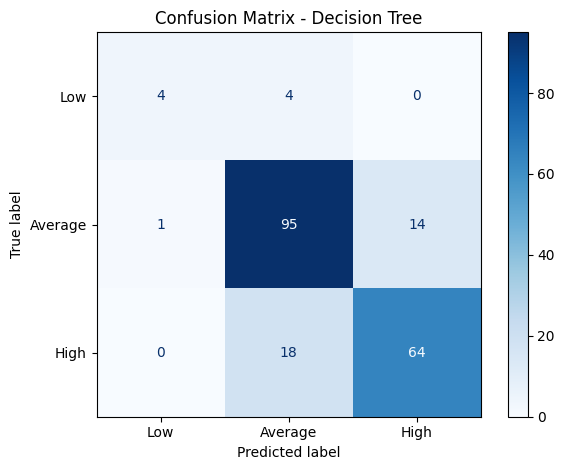

In [ ]:
best_model_name = results_df.sort_values(
    by="F1-Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model by weighted F1-score:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Average", "High"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Average", "High"]
)

display.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()



Explanation:

A confusion matrix compares actual performance categories with predicted categories.

Correct predictions appear on the main diagonal. Values outside the diagonal represent misclassifications.

This visualization helps identify which performance categories the model predicts correctly and which categories it confuses.

## Step 8: Visualize the Dataset and Model Performance

## 8.1 Distribution of Mathematics Scores

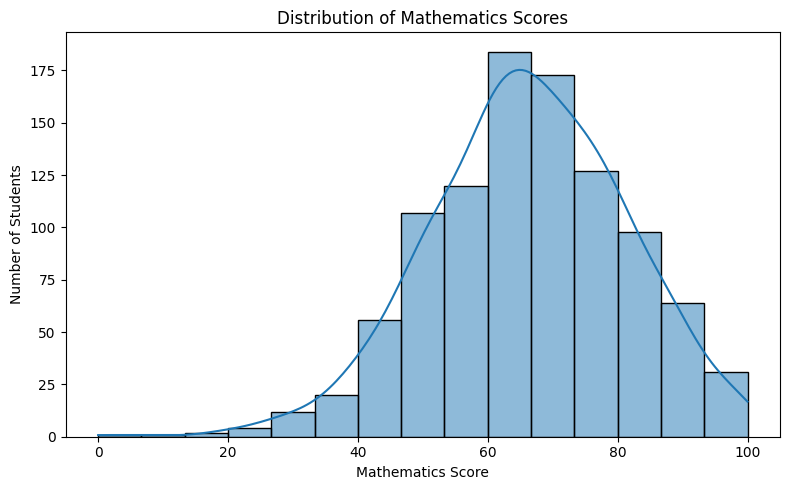

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="math score",
    bins=15,
    kde=True
)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

Explanation:

This histogram shows how mathematics scores are distributed among the students.

## 8.2 Distribution of Performance Categories

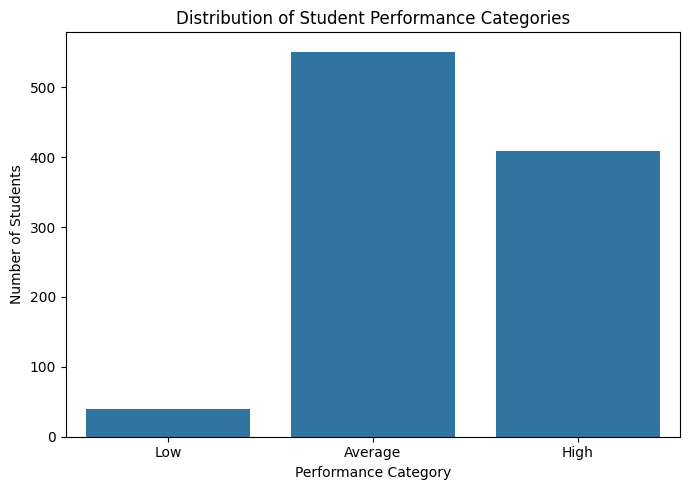

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="Performance",
    order=["Low", "Average", "High"]
)

plt.title("Distribution of Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

Explanation:

This chart shows the number of students classified into each performance category.

## 8.3 Comparison of Classification Models

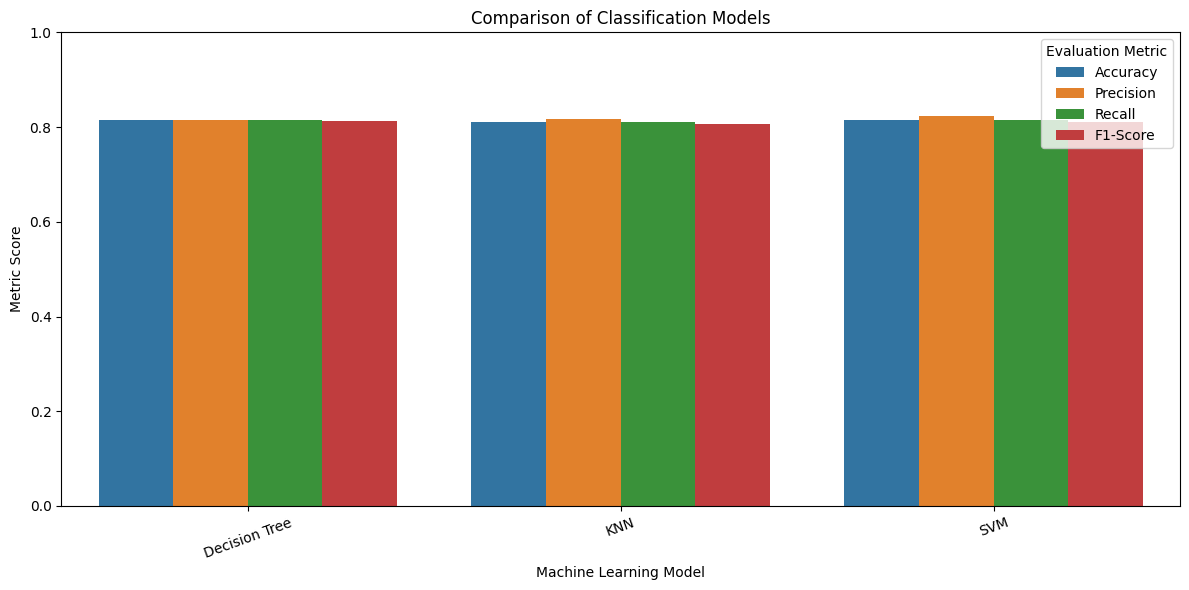

In [ ]:
plot_data = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Metric Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()



Explanation:

The grouped bar chart compares the five classification models using accuracy, precision, recall, and F1-score.

## 8.4 Decision Tree Visualization

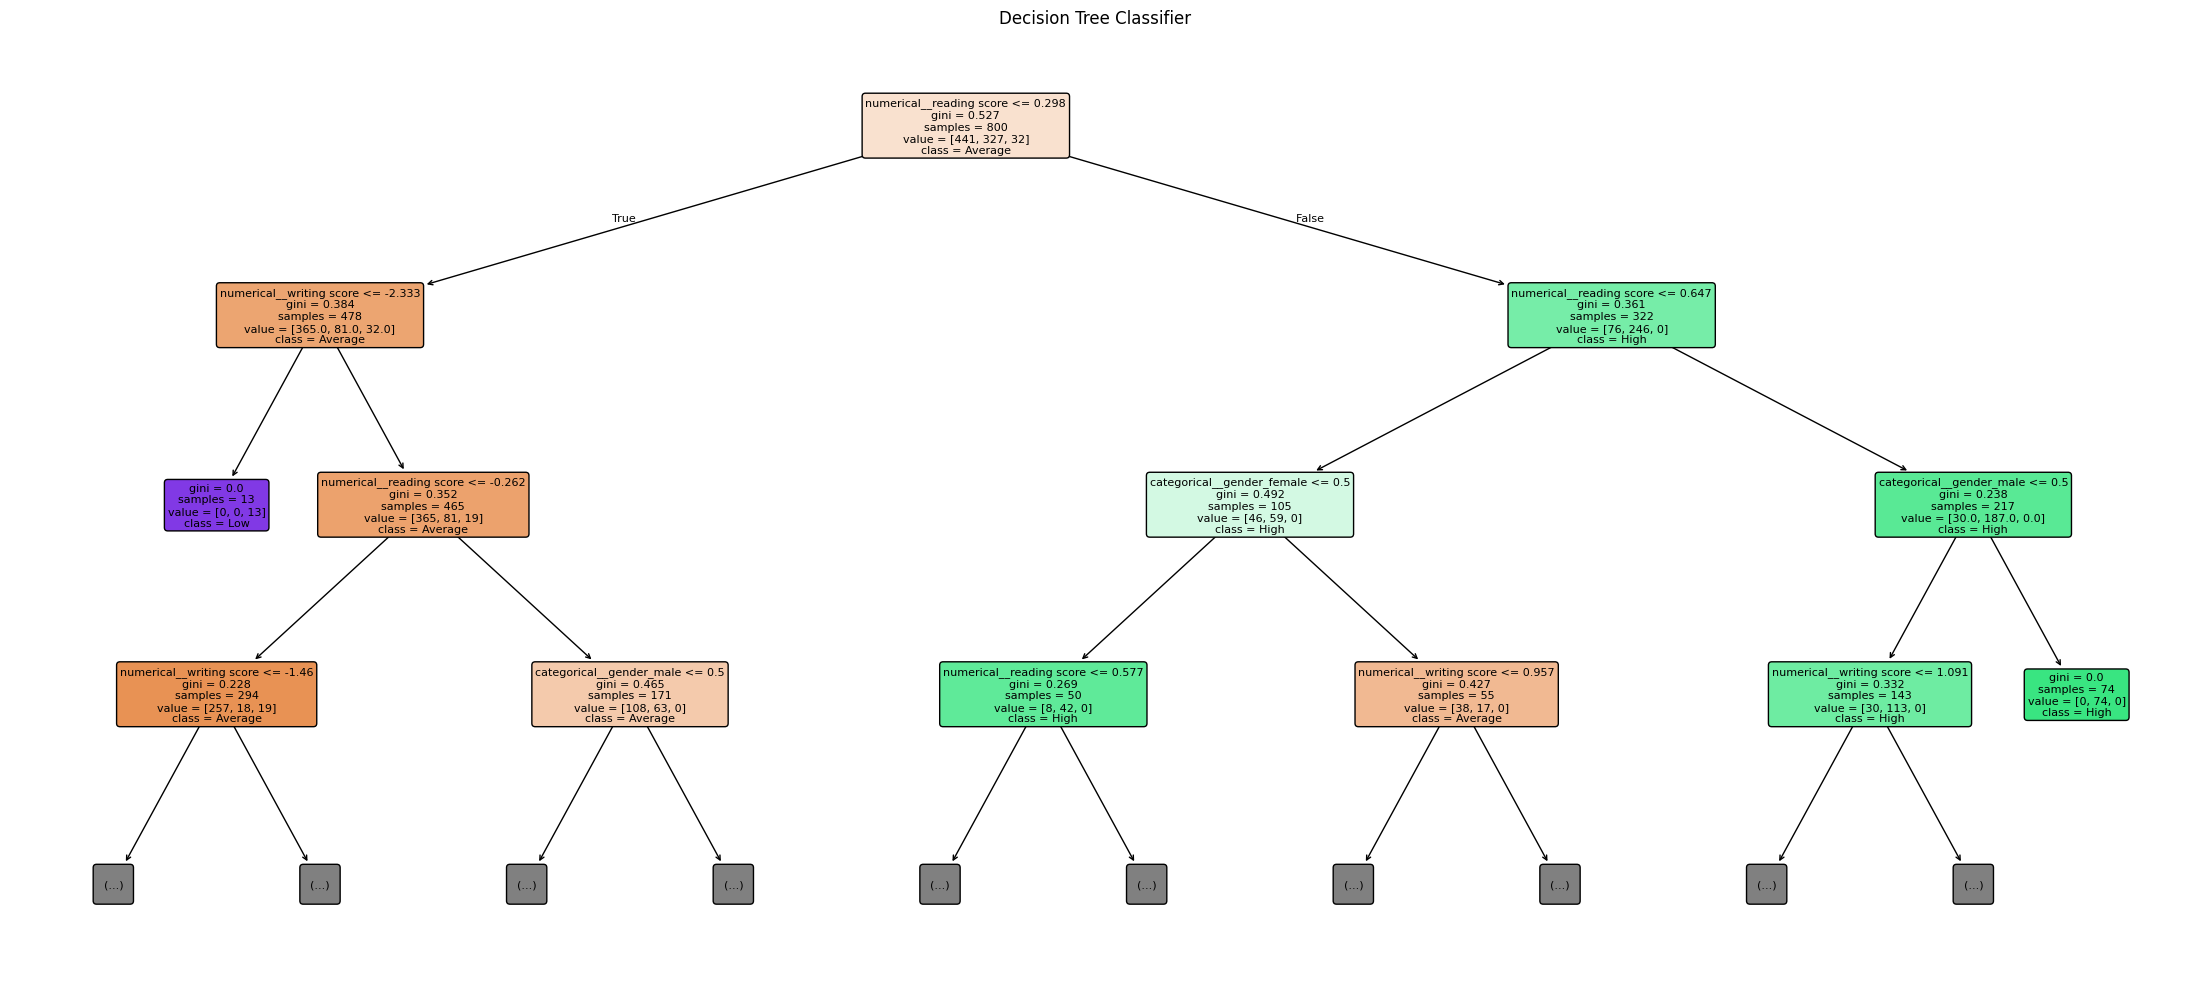

In [ ]:
tree_model = trained_models["Decision Tree"]

tree_classifier = tree_model.named_steps["classifier"]

feature_names = (
    tree_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(22, 10))

plot_tree(
    tree_classifier,
    feature_names=feature_names,
    class_names=tree_classifier.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

Explanation:

The decision tree visualization displays the feature-based rules used to classify students. The displayed tree is limited to a depth of three for readability; the trained model can contain additional levels.

## Step 9: PERFORMANCE EVALUATION METRICS

## 9.1 Accuracy

  Accuracy measures the proportion of correct predictions among all predictions.

  A higher accuracy indicates that the model correctly classifies more test records.
  

## 9.2 Precision

  Precision measures how many predictions assigned to a particular category are correct. Weighted precision combines category-specific precision values while accounting for category sizes.


## 9.3 Recall

  Recall measures how many actual members of a category the model correctly identifies. Weighted recall accounts for the number of observations in each category.


## 9.4 F1-Score

  F1-score combines precision and recall into a single metric. The weighted F1-score is used to compare the overall classification performance of the models.


## 9.5 Confusion Matrix

  The confusion matrix displays the number of correct and incorrect predictions for the Low, Average, and High categories.

  These metrics provide complementary information, so a model should not be selected using accuracy alone when class-level performance is important.

## Step 10: RESULTS AND ANALYSIS

## 10.1 Model Comparison

After running the Python code, the program generates a comparison table containing the actual test-set results.

The actual values should be copied from the Model Comparison table produced by the Python program.

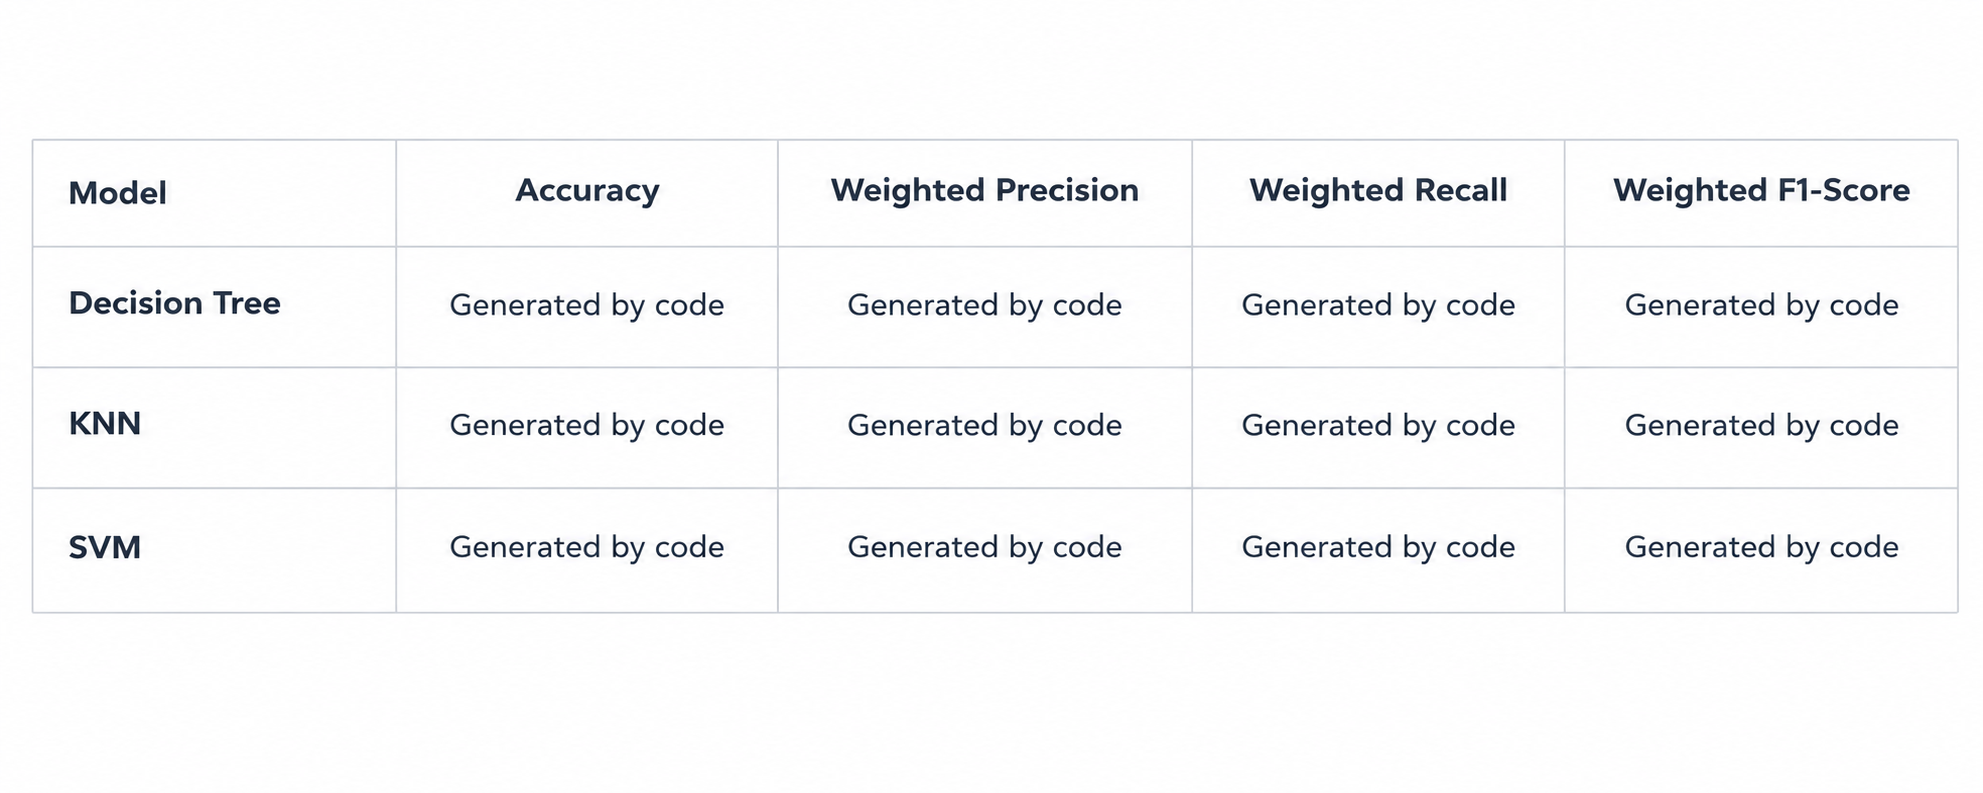

## 10.2 Analysis of Results

The five algorithms use different approaches to classify student performance.

*   Decision Tree: Uses a set of decision rules and provides a visual representation of the classification process.

*   KNN: Uses similarities between students' input features to predict performance categories.

*   SVM: Learns decision boundaries that separate the performance categories.

The best-performing model is identified by sorting the results according to weighted F1-score. Accuracy and the confusion matrix should also be reviewed before drawing a final conclusion.

The exact ranking depends on the selected dataset, category thresholds, train-test split, preprocessing, and model parameters. Therefore, the best model should be identified from the actual output rather than assumed in advance.


## Step 11: DISCUSSION

This project demonstrates how machine learning can be used to classify student mathematics performance.

The dataset combines student background information with reading and writing scores. These attributes are used to predict the student's mathematics performance category.

The preprocessing stage converts categorical attributes into numerical features and standardizes numerical inputs. The same training and testing split is used for all five models to support a consistent comparison.

The classification metrics help determine how well each algorithm predicts the three performance categories. The visualizations provide additional information about score distributions, class balance, classification errors, and decision-making rules.

However, the model identifies statistical patterns in the dataset. It does not establish that a particular student characteristic causes a particular academic outcome. Predictions should be interpreted carefully and should not be used as the sole basis for decisions about students.

## Step 12: CONCLUSION

The Student Performance Prediction project demonstrates the application of machine learning classification algorithms to educational data analysis.

The project uses the StudentsPerformance.csv dataset containing 1,000 student records and eight attributes. Mathematics scores are converted into Low, Average, and High performance categories to make the task suitable for classification.

The dataset is preprocessed using OneHotEncoder and StandardScaler. It is then divided into training and testing sets using an 80:20 ratio.

Five classification algorithms are implemented: Decision Tree, KNN, SVM, Random Forest, and Gradient Boosting.

Their performances are evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, and confusion matrices. Graphical visualizations are used to compare the models and examine their predictions.

The best-performing model is selected based on the evaluation results generated by the program. Since the classification experiment must be run to obtain its metrics, no unverified accuracy values are assumed in this report.

Overall, the project demonstrates how machine learning can help analyze student performance patterns and classify academic outcomes. The results should be treated as estimates, and further testing on additional student data would be needed before using such a model in real educational settings.

## Step 13: LIMITATIONS



1.   The dataset contains a limited number of student records and attributes.
2.   The Low, Average, and High categories are defined by project-specific score thresholds.

1.   Model performance depends on the training and testing split and the selected parameters.
2.   The dataset may not represent every school, educational system, or student population.


1.   The model identifies predictive relationships but does not establish causal relationships.
2.   Predictions may reflect biases present in the source data.

1.   The classification model predicts a category rather than an exact mathematics score.








## Step 14: FUTURE ENHANCEMENTS

The project can be extended in several ways:

1.   Include additional attributes such as attendance, study hours, assignment marks, and previous examination scores.

1.   Use cross-validation to obtain a more reliable comparison of the classification models.

1.   Tune model parameters to improve predictive performance.
2.   Develop a web application that accepts student details and displays a predicted performance category.


2.   Create an interactive dashboard to visualize student performance and model results.


2.   Investigate fairness and differences in prediction errors across student groups.



1.   Evaluate the models on additional datasets to determine whether their performance generalizes to other student populations.




## Step 15:PROJECT WORKFLOW

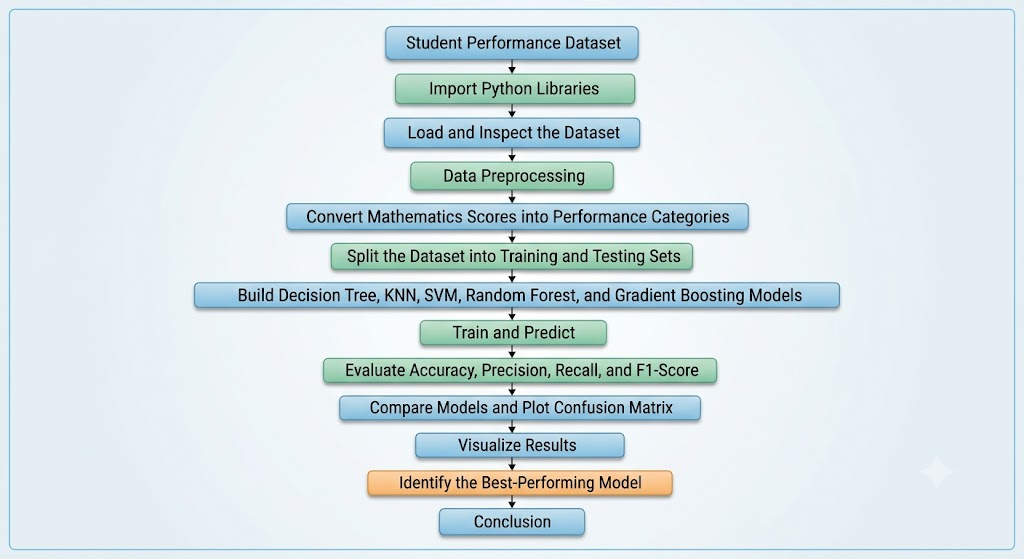

## Step 16: FINAL *SUMMARY*

This case study applies five machine learning classification algorithms to the Student Performance dataset. The numerical mathematics scores are converted into three performance categories, and the models are trained to predict those categories using student background information and reading and writing scores.

The project covers dataset inspection, preprocessing, model development, evaluation, visualization, and comparison. The final model selection is based on the metrics produced by the Python implementation.

The project demonstrates the potential of machine learning for educational data analysis while emphasizing the need for careful evaluation, responsible interpretation, and further validation.